# Estimating Test Error: The Validation Set Approach

**Connection:** Train/test error → bias–variance tradeoff → model selection → **resampling to estimate test MSE** (Validation Set → K-fold CV → Bootstrap)

---

## Recap: Train vs. Test Error

**Fitting the model** (least squares on training data):

$$\hat{\theta}=\arg\min_{\theta}\sum_{i\in D_{Tr}}\big(y_i-f(x_i;\theta)\big)^2 \quad\text{(RSS)}$$

**Training error** (how well we fit data we already saw):

$$MSE_{train}=\frac{1}{N_{Tr}}\sum_{i\in D_{Tr}}\big(y_i-f(x_i;\hat{\theta})\big)^2$$

**Test error** (how well we predict *new* data, which is what we actually care about):

$$MSE_{test}=\frac{1}{N_{Te}}\sum_{i\in D_{Te}}\big(y_i-f(x_i;\hat{\theta})\big)^2$$

- **Train MSE** always decreases as flexibility increases.
- **Test MSE** is U-shaped:
  - Too rigid → **high bias** (underfitting)
  - Too flexible → **high variance** (overfitting)
- **Problem:** in practice we only have *one* labeled dataset, so we have no separate test set. We must **estimate** the test MSE by holding out part of our data.

---

## The Validation Set Approach

**Idea:** Pretend part of your data is "new" by hiding it during training.

1. **Randomly split** the $N$ points into a training subset $D_{TS}$ and a validation subset $D_{VS}$ (e.g., 50/50).
2. **Train** on $D_{TS}$ only to get $\hat{\theta}$.
3. **Evaluate** on $D_{VS}$:

$$MSE_{VS}=\frac{1}{N_{VS}}\sum_{i\in D_{VS}}\big(y_i-f(x_i;\hat{\theta})\big)^2 \;\approx\; MSE_{test}$$

**Why random, not "first half / second half"?** Adjacent points can be correlated (e.g., data sorted by time or by some feature), so a middle split could give two non-comparable subsets.

---

## Using It for Model Selection (Auto dataset)

- Data: horsepower (input) → mpg (output). Models: polynomials of degree $d=1,2,3,\dots$
- For each $d$: train on $D_{TS}$, compute $MSE_{VS}$, then plot $MSE_{VS}$ vs. $d$.
- **Elbow at $d=2$** → pick the quadratic.
- **Parsimony rule:** if a higher degree only reduces error slightly, **choose the simpler model** (easier to interpret, less likely to overfit).

---

## Drawbacks (Exam-Relevant)

| # | Drawback | Why it happens |
|---|----------|----------------|
| 1 | **High variability:** $MSE_{VS}$ changes a lot depending on the random split | Different splits put different points in validation |
| 2 | **Wastes data:** only ~half the points are used for training | Model trained on less data is worse |
| 3 | **Overestimates test MSE** | Model trained on fewer points than the final model will use |

*These are exactly the problems **K-fold CV** (next topic) is designed to fix.*

---

## ⚠️ Transcript Clarifications

- The transcript calls the subsets "$D_{TS}$" and "$D_{BS}$" in one spot. This is a transcription slip; the validation subset is **$D_{VS}$**.
- Drawback 3: it overestimates because the model is fit on only part of the data. Once you refit on **all** data for the final model, it will usually perform *slightly better* than the validation estimate suggested.

---

## Formula Guide

- **Memorize:** $MSE=\frac{1}{n}\sum(y_i-\hat{y}_i)^2$ (applied to train, validation, or test set)
- **Understand conceptually:** the RSS minimization, which is just least squares written for a general model $f(x;\theta)$
- **Theory only:** nothing else here; this lecture is mostly procedural.

---

## Key Takeaways

- **Training error is a poor guide** for model quality; it always improves with flexibility.
- The **validation set approach** estimates test MSE by training on a random subset and evaluating on the held-out remainder.
- Splits must be **random**, not sequential, to avoid correlation between subsets.
- Plot $MSE_{VS}$ vs. model flexibility and pick the **elbow**; prefer the **simpler model** when gains are small.
- **Drawback 1:** the estimate is **highly variable** across random splits.
- **Drawback 2 and 3:** it **wastes data** and **overestimates** the true test MSE.
- These weaknesses motivate **K-fold cross-validation**.

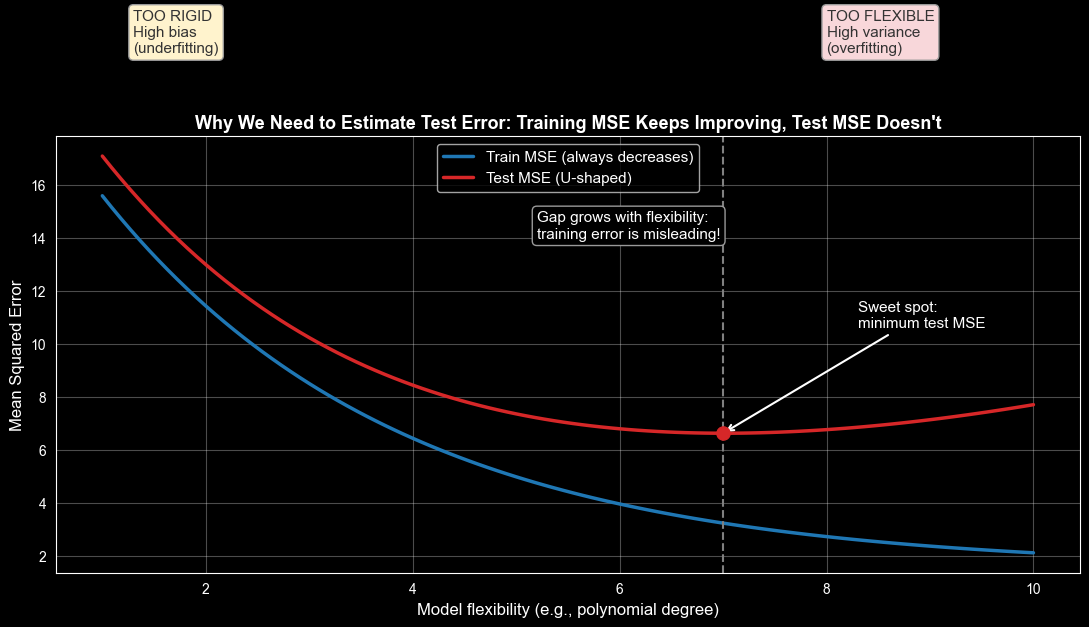

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Illustrative curves (U-shaped test MSE, monotonically decreasing train MSE)
flex = np.linspace(1, 10, 100)
train_mse = 20 * np.exp(-0.35 * flex) + 1.5
test_mse = 20 * np.exp(-0.35 * flex) + 1.5 + 0.18 * (flex - 1) ** 1.9 * 0.35 + 1.5

best = flex[np.argmin(test_mse)]

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.plot(flex, train_mse, color="#1f77b4", lw=2.5, label="Train MSE (always decreases)")
ax.plot(flex, test_mse, color="#d62728", lw=2.5, label="Test MSE (U-shaped)")
ax.axvline(best, color="gray", ls="--", lw=1.5)
ax.scatter([best], [test_mse.min()], color="#d62728", s=90, zorder=5)

ax.annotate("Sweet spot:\nminimum test MSE", xy=(best, test_mse.min()),
            xytext=(best + 1.3, test_mse.min() + 4),
            fontsize=11, arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(1.3, 21, "TOO RIGID\nHigh bias\n(underfitting)", fontsize=11, color="#333",
        bbox=dict(boxstyle="round", fc="#fff3cd", ec="#999"))
ax.text(8.0, 21, "TOO FLEXIBLE\nHigh variance\n(overfitting)", fontsize=11, color="#333",
        bbox=dict(boxstyle="round", fc="#f8d7da", ec="#999"))
ax.text(5.2, 14, "Gap grows with flexibility:\ntraining error is misleading!",
        fontsize=11, bbox=dict(boxstyle="round", fc="black", ec="#999"))

ax.set_title("Why We Need to Estimate Test Error: Training MSE Keeps Improving, Test MSE Doesn't",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Model flexibility (e.g., polynomial degree)", fontsize=12)
ax.set_ylabel("Mean Squared Error", fontsize=12)
ax.legend(fontsize=11, loc="upper center")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

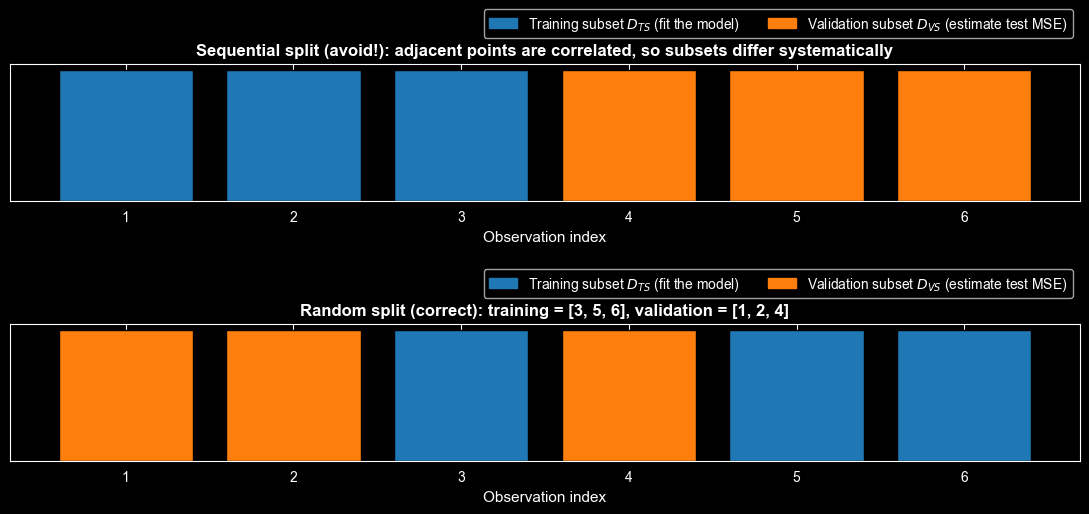

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

rng = np.random.default_rng(4)
n = 6
idx = np.arange(1, n + 1)
train_idx = rng.choice(idx, size=3, replace=False)   # randomly pick 3 for training
val_idx = np.setdiff1d(idx, train_idx)                # the rest become validation

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5))

# Top: BAD sequential split
colors_seq = ["#1f77b4"] * 3 + ["#ff7f0e"] * 3
axes[0].bar(idx, [1] * n, color=colors_seq, edgecolor="black")
axes[0].set_title("Sequential split (avoid!): adjacent points are correlated, so subsets differ systematically",
                  fontsize=12, fontweight="bold")

# Bottom: GOOD random split
colors_rand = ["#1f77b4" if i in train_idx else "#ff7f0e" for i in idx]
axes[1].bar(idx, [1] * n, color=colors_rand, edgecolor="black")
axes[1].set_title(f"Random split (correct): training = {sorted(train_idx.tolist())}, validation = {sorted(val_idx.tolist())}",
                  fontsize=12, fontweight="bold")

for ax in axes:
    ax.set_yticks([])
    ax.set_xticks(idx)
    ax.set_xlabel("Observation index", fontsize=11)
    ax.legend(handles=[Patch(color="#1f77b4", label="Training subset $D_{TS}$ (fit the model)"),
                       Patch(color="#ff7f0e", label="Validation subset $D_{VS}$ (estimate test MSE)")],
              fontsize=10, loc="upper right", bbox_to_anchor=(1.0, 1.45), ncol=2)
plt.tight_layout()
plt.subplots_adjust(hspace=0.9)
plt.show()

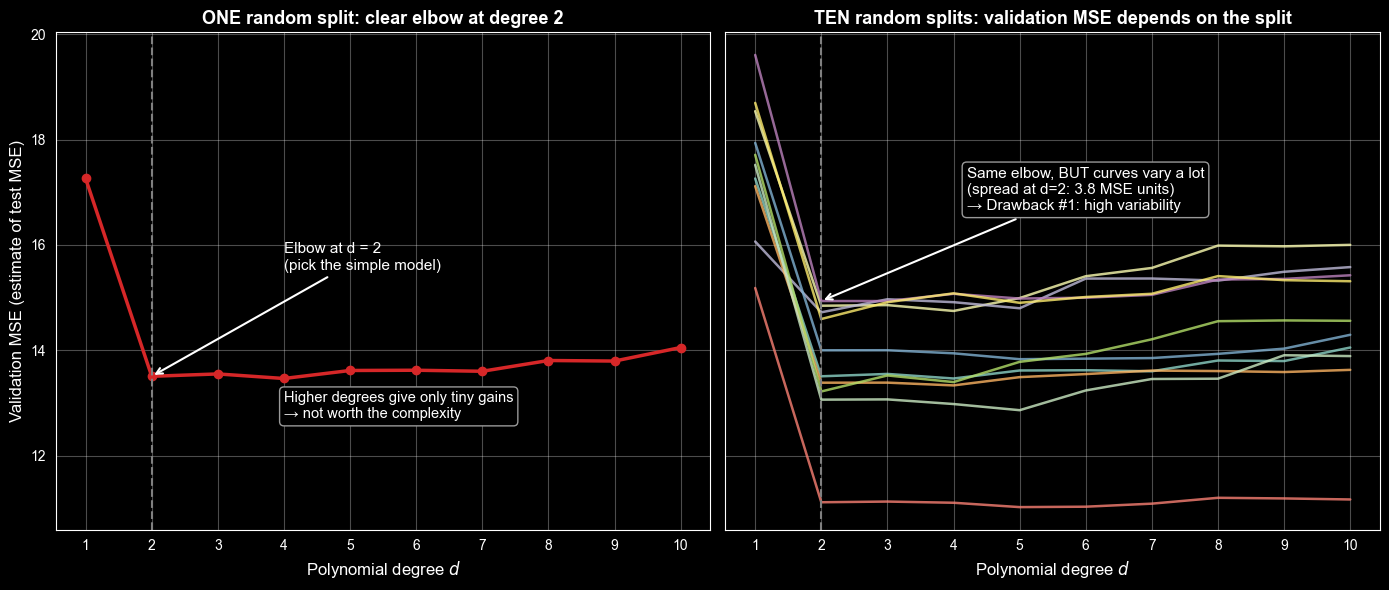

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Simulate an Auto-like dataset: mpg decreases with horsepower, mildly curved (true degree = 2)
rng = np.random.default_rng(0)
n = 392
hp = rng.uniform(46, 230, n)
hp_s = (hp - hp.mean()) / hp.std()                     # standardize for numerical stability
mpg = 24 - 6 * hp_s + 2.2 * hp_s**2 + rng.normal(0, 3.6, n)

degrees = range(1, 11)

def validation_mse_curve(seed):
    """One random 50/50 split -> validation MSE for each polynomial degree."""
    r = np.random.default_rng(seed)
    perm = r.permutation(n)                             # RANDOM partition
    tr, va = perm[: n // 2], perm[n // 2 :]
    mses = []
    for d in degrees:
        coefs = np.polyfit(hp_s[tr], mpg[tr], d)        # train on training subset only
        pred = np.polyval(coefs, hp_s[va])              # predict on validation subset
        mses.append(np.mean((mpg[va] - pred) ** 2))     # MSE_VS
    return mses

curves = np.array([validation_mse_curve(s) for s in range(10)])

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Left: single split
axes[0].plot(degrees, curves[0], "o-", color="#d62728", lw=2.5)
axes[0].axvline(2, color="gray", ls="--")
axes[0].annotate("Elbow at d = 2\n(pick the simple model)", xy=(2, curves[0][1]),
                 xytext=(4, curves[0].max() * 0.9), fontsize=11,
                 arrowprops=dict(arrowstyle="->", lw=1.5))
axes[0].text(4.0, curves[0].min() - 0.2 * (curves[0].max() - curves[0].min()),
             "Higher degrees give only tiny gains\n→ not worth the complexity",
             fontsize=10.5, bbox=dict(boxstyle="round", fc="black", ec="#999"))
axes[0].set_title("ONE random split: clear elbow at degree 2", fontsize=13, fontweight="bold")

# Right: 10 splits
for c in curves:
    axes[1].plot(degrees, c, lw=1.8, alpha=0.8)
axes[1].axvline(2, color="gray", ls="--")
spread = curves[:, 1].max() - curves[:, 1].min()
axes[1].annotate(f"Same elbow, BUT curves vary a lot\n(spread at d=2: {spread:.1f} MSE units)\n→ Drawback #1: high variability",
                 xy=(2, curves[:, 1].max()), xytext=(4.2, curves.max() * 0.85),
                 fontsize=11, arrowprops=dict(arrowstyle="->", lw=1.5),
                 bbox=dict(boxstyle="round", fc="black", ec="#999"))
axes[1].set_title("TEN random splits: validation MSE depends on the split", fontsize=13, fontweight="bold")

for ax in axes:
    ax.set_xlabel("Polynomial degree $d$", fontsize=12)
    ax.grid(alpha=0.3)
    ax.set_xticks(list(degrees))
axes[0].set_ylabel("Validation MSE (estimate of test MSE)", fontsize=12)
plt.tight_layout()
plt.show()

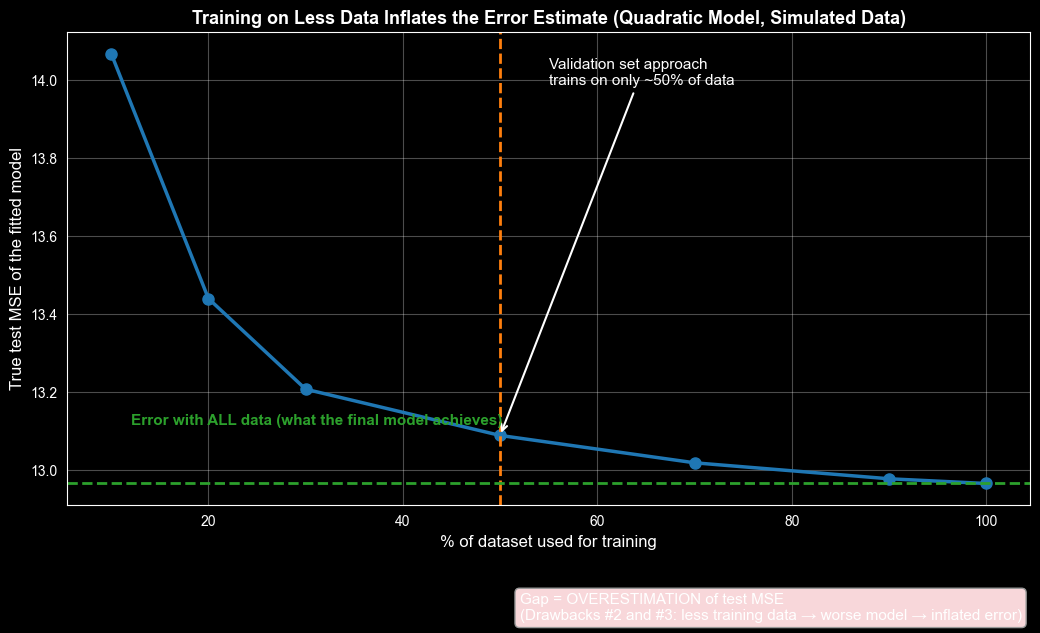

In [4]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
n = 392
x = rng.uniform(-2, 2, n)
y = 24 - 6 * x + 2.2 * x**2 + rng.normal(0, 3.6, n)

# Large fixed test set from the same process = proxy for "true" test MSE
x_big = rng.uniform(-2, 2, 50_000)
y_big = 24 - 6 * x_big + 2.2 * x_big**2 + rng.normal(0, 3.6, 50_000)

d = 2
fractions = [0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0]
avg_err = []
for f in fractions:
    errs = []
    for rep in range(200):
        m = max(int(f * n), d + 2)
        sub = rng.choice(n, size=m, replace=False)       # train on a fraction of the data
        coefs = np.polyfit(x[sub], y[sub], d)
        errs.append(np.mean((y_big - np.polyval(coefs, x_big)) ** 2))
    avg_err.append(np.mean(errs))

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.plot([f * 100 for f in fractions], avg_err, "o-", color="#1f77b4", lw=2.5, ms=8)
ax.axvline(50, color="#ff7f0e", ls="--", lw=2)
ax.axhline(avg_err[-1], color="#2ca02c", ls="--", lw=2)

ax.annotate("Validation set approach\ntrains on only ~50% of data",
            xy=(50, avg_err[3]), xytext=(55, avg_err[3] + 0.9), fontsize=11,
            arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(12, avg_err[-1] + 0.15, "Error with ALL data (what the final model achieves)",
        color="#2ca02c", fontsize=11, fontweight="bold")
ax.text(52, avg_err[-1] - 0.35,
        "Gap = OVERESTIMATION of test MSE\n(Drawbacks #2 and #3: less training data → worse model → inflated error)",
        fontsize=11, bbox=dict(boxstyle="round", fc="#f8d7da", ec="#999"))

ax.set_title("Training on Less Data Inflates the Error Estimate (Quadratic Model, Simulated Data)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("% of dataset used for training", fontsize=12)
ax.set_ylabel("True test MSE of the fitted model", fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# K-Fold Cross-Validation

**Connection:** Train/test error → [Validation Set Approach](#) (high variance, wastes data) → **K-fold CV (fixes both)** → Bootstrap

---

## The Problem K-Fold Solves

The validation set approach uses **one** random split. That makes the test-MSE estimate noisy and trains on only ~50% of the data.

**K-fold idea:** Don't split once. Split into $K$ folds and let *every* fold take a turn as the validation set. Then **average** the results.

---

## The Algorithm

**Step 1: Partition.** Randomly split the data $D$ (with $N$ points) into $K$ folds of nearly equal size: $D_1, D_2, \dots, D_K$ with sizes $N_1, \dots, N_K$.

**Step 2: Loop** for $k = 1, \dots, K$:

1. **Train** on everything *except* fold $k$, i.e. on $D \setminus D_k$:

$$\hat{\theta}_k=\arg\min_\theta \sum_{i\in D\setminus D_k}\big(y_i-f(x_i;\theta)\big)^2$$

2. **Validate** on the left-out fold $D_k$:

$$MSE_k=\frac{1}{N_k}\sum_{i\in D_k}\big(y_i-f(x_i;\hat{\theta}_k)\big)^2$$

**Step 3: Combine** with a weighted average (weights = fraction of data in each fold):

$$\boxed{CV_{(K)}=\sum_{k=1}^{K}\frac{N_k}{N}\,MSE_k}$$

> **Intuition:** Every point gets used for validation **exactly once** and for training **K−1 times**. If folds are equal-sized, the weights are all $1/K$ and this is just the plain average.

**Tiny example:** $N=9$, $K=3$ → three folds of 3 points. Fit 1 trains on $D_2\cup D_3$ (6 points), tests on $D_1$; and so on.

---

## Special Case: Leave-One-Out CV (LOOCV)

Set $K=N$ → each point is its own fold.

- Train on $N-1$ points, test on the single left-out point. Repeat $N$ times and average.
- **No random partition needed** (the split is deterministic).
- Cost: $N$ model fits (expensive for big datasets).

---

## Results on the Auto Data (Polynomial Degree)

- **10-fold CV:** repeating with different random partitions gives curves that are **very close to each other**. Compare this with the validation set approach, where curves were all over the place.
- **10-fold and LOOCV** both show the elbow at **degree 2** → pick the quadratic.

---

## Advantages Over the Validation Set Approach

| Advantage | Why |
|---|---|
| **Less volatile estimate** | Averaging $K$ folds smooths out the luck of any one split |
| **Uses more data for training** | Each fit uses $\frac{K-1}{K}N$ points (e.g., 90% for $K=10$) vs. 50% |
| **Less overestimation of test MSE** | Training sets are closer in size to the full dataset |

---

## K-Fold for Classification

Same three steps. Only the **error measure** changes: use the **misclassification rate**, not squared error.

**Training (equivalent formulations):** minimize misclassification = maximize correct predictions:

$$\hat{\theta}_k=\arg\max_\theta\sum_{i\in D\setminus D_k}\delta\big(y_i,\ \hat{y}_i(\theta)\big),\qquad \delta=\begin{cases}1&\text{if correct}\\0&\text{if wrong}\end{cases}$$

**Validation error in fold $k$:**

$$Err_k=\frac{1}{N_k}\sum_{i\in D_k}\Big[1-\delta\big(y_i,\hat{y}_i(\hat{\theta}_k)\big)\Big]=\frac{\#\text{misclassified in }D_k}{N_k}$$

**Final CV estimate:**

$$CV_{(K)}=\sum_{k=1}^{K}\frac{N_k}{N}\,Err_k$$

---

## ⚠️ Transcript Clarifications

- The transcript says "RSE" in several places; the quantity being minimized is the **RSS** (residual sum of squares).
- "Evolution of the test MSE versus the degree of the polynomial **fading**" = polynomial **fitting**.
- The lecture says K-fold gives a "less overestimated" MSE. Note this is *less*, not *none*: each fit still uses only $\frac{K-1}{K}$ of the data, so a small upward bias remains.
- *Beyond the lecture (useful to know):* LOOCV is the least biased but its $N$ training sets are almost identical, so the estimates are highly correlated. In practice **$K=5$ or $K=10$** is the usual sweet spot.

---

## Formula Guide

- **Memorize:** $CV_{(K)}=\sum_k \frac{N_k}{N}MSE_k$ and the misclassification version with $Err_k$
- **Understand conceptually:** the per-fold training step ($\arg\min$ on $D\setminus D_k$), and the $\delta$ (indicator) trick for counting correct labels
- **Theory only:** the $\arg\max$ form of the classifier training objective (just the flip side of minimizing errors)

---

## Key Takeaways

- **K-fold CV** splits data into $K$ random folds; each fold takes one turn as validation while the model trains on the other $K-1$.
- The estimate is the **weighted average** $\sum_k \frac{N_k}{N}MSE_k$ of the per-fold errors.
- **LOOCV** is the special case $K=N$ (no randomness, but $N$ fits).
- Compared with a single validation split, K-fold is **less volatile**, **uses more training data**, and **overestimates test MSE less**.
- Use K-fold CV to choose model flexibility: pick the **elbow** (degree 2 for Auto) and prefer the simpler model.
- For **classification**, replace squared error with the **misclassification rate**; the structure is identical.|

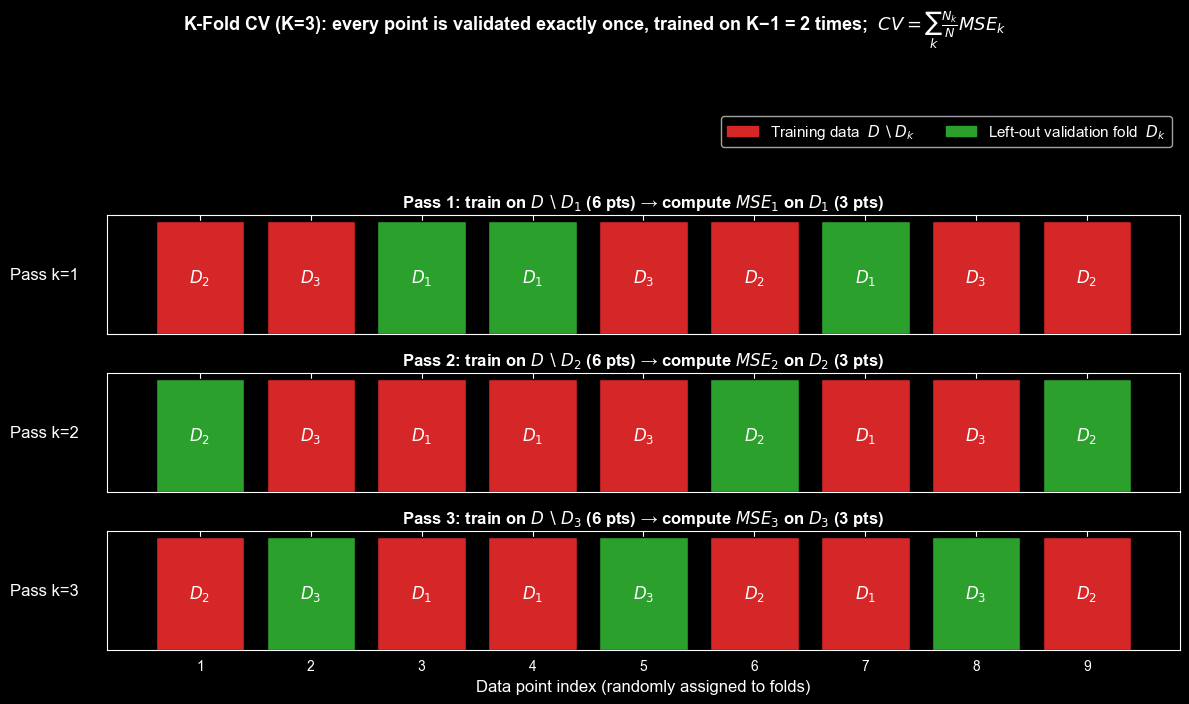

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# N = 9 points randomly assigned to K = 3 folds of size 3
rng = np.random.default_rng(6)
N, K = 9, 3
perm = rng.permutation(np.arange(1, N + 1))
folds = np.array_split(perm, K)                       # D1, D2, D3

fig, axes = plt.subplots(K, 1, figsize=(12, 7), sharex=True)
for k, ax in enumerate(axes):
    # Which fold does each point belong to?
    fold_of = {pt: j for j, f in enumerate(folds) for pt in f}
    colors = ["#2ca02c" if fold_of[i] == k else "#d62728" for i in range(1, N + 1)]
    ax.bar(range(1, N + 1), [1] * N, color=colors, edgecolor="black")
    for i in range(1, N + 1):
        ax.text(i, 0.5, f"$D_{fold_of[i]+1}$", ha="center", va="center",
                color="white", fontsize=12, fontweight="bold")
    ax.set_yticks([])
    ax.set_ylabel(f"Pass k={k+1}", fontsize=12, rotation=0, labelpad=45, va="center")
    ax.set_title(rf"Pass {k+1}: train on $D \setminus D_{k+1}$ (6 pts) → compute $MSE_{k+1}$ on $D_{k+1}$ (3 pts)",
                 fontsize=12, fontweight="bold")

axes[-1].set_xticks(range(1, N + 1))
axes[-1].set_xlabel("Data point index (randomly assigned to folds)", fontsize=12)
axes[0].legend(handles=[Patch(color="#d62728", label="Training data  $D \\setminus D_k$"),
                        Patch(color="#2ca02c", label="Left-out validation fold  $D_k$")],
               fontsize=11, loc="upper right", bbox_to_anchor=(1.0, 1.9), ncol=2)
fig.suptitle(r"K-Fold CV (K=3): every point is validated exactly once, trained on K−1 = 2 times;  $CV=\sum_k \frac{N_k}{N}MSE_k$",
             fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

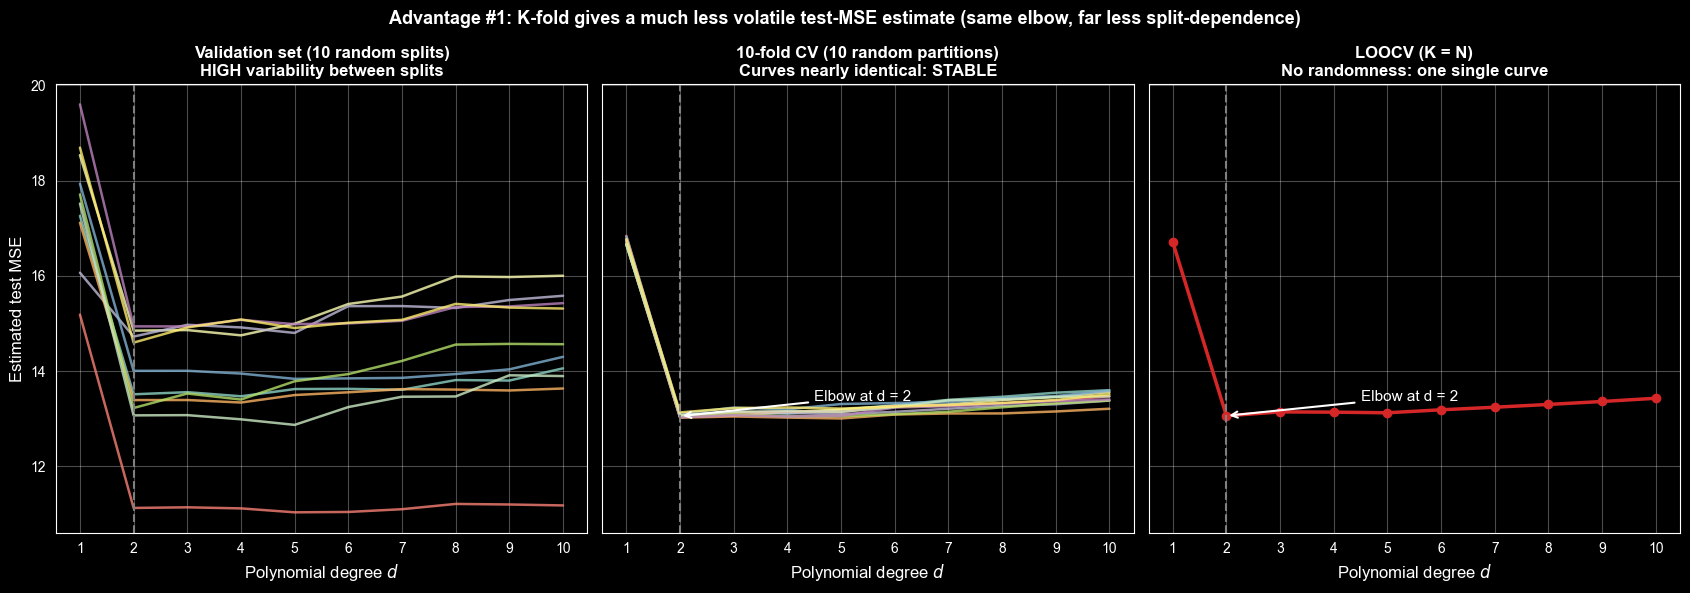

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Auto-style simulated data (true relationship is quadratic)
rng = np.random.default_rng(0)
n = 392
hp = rng.uniform(46, 230, n)
x = (hp - hp.mean()) / hp.std()
y = 24 - 6 * x + 2.2 * x**2 + rng.normal(0, 3.6, n)
degrees = list(range(1, 11))

def cv_curve(K, seed):
    """K-fold CV estimate of test MSE for each polynomial degree."""
    perm = np.random.default_rng(seed).permutation(n)
    folds = np.array_split(perm, K)
    curve = []
    for d in degrees:
        total = 0.0
        for k in range(K):
            va = folds[k]
            tr = np.concatenate([folds[j] for j in range(K) if j != k])
            coefs = np.polyfit(x[tr], y[tr], d)                       # train on D \ D_k
            mse_k = np.mean((y[va] - np.polyval(coefs, x[va])) ** 2)  # MSE_k on D_k
            total += len(va) / n * mse_k                              # weight N_k / N
        curve.append(total)
    return curve

def val_set_curve(seed):
    perm = np.random.default_rng(seed).permutation(n)
    tr, va = perm[: n // 2], perm[n // 2:]
    return [np.mean((y[va] - np.polyval(np.polyfit(x[tr], y[tr], d), x[va])) ** 2) for d in degrees]

val_curves = [val_set_curve(s) for s in range(10)]
kf_curves = [cv_curve(10, s) for s in range(10)]
loo_curve = cv_curve(n, 0)  # K = N -> leave-one-out (deterministic)

fig, axes = plt.subplots(1, 3, figsize=(17, 6), sharey=True)
for c in val_curves: axes[0].plot(degrees, c, lw=1.8, alpha=0.8)
for c in kf_curves:  axes[1].plot(degrees, c, lw=1.8, alpha=0.8)
axes[2].plot(degrees, loo_curve, "o-", color="#d62728", lw=2.5)

titles = ["Validation set (10 random splits)\nHIGH variability between splits",
          "10-fold CV (10 random partitions)\nCurves nearly identical: STABLE",
          "LOOCV (K = N)\nNo randomness: one single curve"]
for ax, t in zip(axes, titles):
    ax.axvline(2, color="gray", ls="--", lw=1.5)
    ax.set_title(t, fontsize=12, fontweight="bold")
    ax.set_xlabel("Polynomial degree $d$", fontsize=12)
    ax.set_xticks(degrees)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Estimated test MSE", fontsize=12)
axes[1].annotate("Elbow at d = 2", xy=(2, kf_curves[0][1]), xytext=(4.5, max(kf_curves[0]) * 0.8),
                 fontsize=11, arrowprops=dict(arrowstyle="->", lw=1.5))
axes[2].annotate("Elbow at d = 2", xy=(2, loo_curve[1]), xytext=(4.5, max(loo_curve) * 0.8),
                 fontsize=11, arrowprops=dict(arrowstyle="->", lw=1.5))
fig.suptitle("Advantage #1: K-fold gives a much less volatile test-MSE estimate (same elbow, far less split-dependence)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

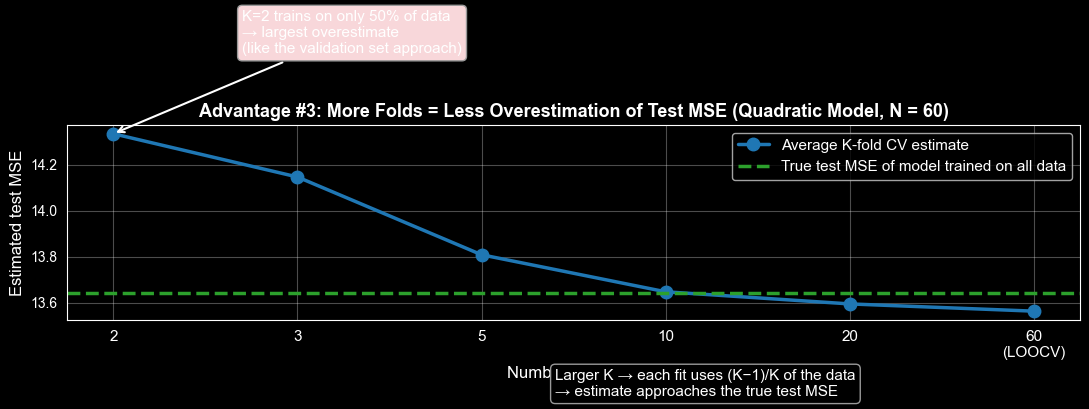

In [7]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(3)
n, d = 60, 2  # small dataset makes the effect easy to see

def make_data(m):
    x = rng.uniform(-2, 2, m)
    return x, 24 - 6 * x + 2.2 * x**2 + rng.normal(0, 3.6, m)

# "True" test MSE of a model trained on ALL n points (large fresh test set)
x_big, y_big = make_data(100_000)
true_errs, cv_by_K = [], {}
Ks = [2, 3, 5, 10, 20, n]  # K = n is LOOCV
reps = 80

for rep in range(reps):
    x, y = make_data(n)
    true_errs.append(np.mean((y_big - np.polyval(np.polyfit(x, y, d), x_big)) ** 2))
    perm = rng.permutation(n)
    for K in Ks:
        folds = np.array_split(perm, K)
        est = 0.0
        for k in range(K):
            va = folds[k]
            tr = np.concatenate([folds[j] for j in range(K) if j != k])
            pred = np.polyval(np.polyfit(x[tr], y[tr], d), x[va])
            est += len(va) / n * np.mean((y[va] - pred) ** 2)
        cv_by_K.setdefault(K, []).append(est)

means = [np.mean(cv_by_K[K]) for K in Ks]
true_mean = np.mean(true_errs)
labels = [str(K) if K != n else f"{n}\n(LOOCV)" for K in Ks]

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.plot(range(len(Ks)), means, "o-", color="#1f77b4", lw=2.5, ms=9, label="Average K-fold CV estimate")
ax.axhline(true_mean, color="#2ca02c", ls="--", lw=2.5, label="True test MSE of model trained on all data")
ax.set_xticks(range(len(Ks)))
ax.set_xticklabels(labels, fontsize=11)
ax.annotate("K=2 trains on only 50% of data\n→ largest overestimate\n(like the validation set approach)",
            xy=(0, means[0]), xytext=(0.7, means[0] + 0.35), fontsize=11,
            arrowprops=dict(arrowstyle="->", lw=1.5), bbox=dict(boxstyle="round", fc="#f8d7da", ec="#999"))
ax.text(2.4, true_mean - 0.45,
        "Larger K → each fit uses (K−1)/K of the data\n→ estimate approaches the true test MSE",
        fontsize=11, bbox=dict(boxstyle="round", fc="black", ec="#999"))
ax.set_title("Advantage #3: More Folds = Less Overestimation of Test MSE (Quadratic Model, N = 60)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Number of folds K", fontsize=12)
ax.set_ylabel("Estimated test MSE", fontsize=12)
ax.legend(fontsize=11, loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

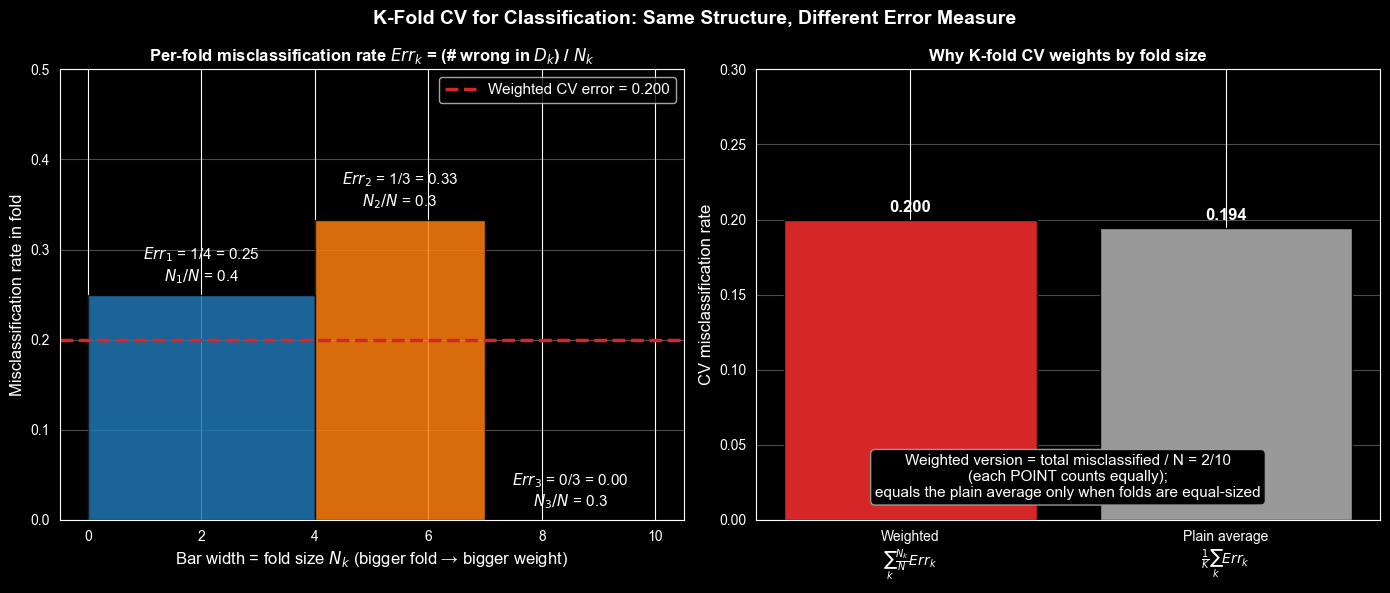

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Example: N = 10 points split into K = 3 UNEQUAL folds
fold_sizes = np.array([4, 3, 3])
misclassified = np.array([1, 1, 0])
err_k = misclassified / fold_sizes                 # Err_k = #wrong / N_k
weights = fold_sizes / fold_sizes.sum()            # N_k / N
cv_weighted = np.sum(weights * err_k)              # = total wrong / N
cv_naive = err_k.mean()                            # plain average (slightly different!)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: per-fold error rate (bar width = fold size)
left_edges = np.concatenate([[0], np.cumsum(fold_sizes)[:-1]])
for k in range(3):
    axes[0].bar(left_edges[k], err_k[k], width=fold_sizes[k], align="edge",
                color=["#1f77b4", "#ff7f0e", "#2ca02c"][k], edgecolor="black", alpha=0.85)
    axes[0].text(left_edges[k] + fold_sizes[k] / 2, err_k[k] + 0.015,
                 f"$Err_{k+1}$ = {misclassified[k]}/{fold_sizes[k]} = {err_k[k]:.2f}\n$N_{k+1}/N$ = {weights[k]:.1f}",
                 ha="center", fontsize=11)
axes[0].axhline(cv_weighted, color="#d62728", ls="--", lw=2.5, label=f"Weighted CV error = {cv_weighted:.3f}")
axes[0].set_ylim(0, 0.5)
axes[0].set_xlabel("Bar width = fold size $N_k$ (bigger fold → bigger weight)", fontsize=12)
axes[0].set_ylabel("Misclassification rate in fold", fontsize=12)
axes[0].set_title("Per-fold misclassification rate $Err_k$ = (# wrong in $D_k$) / $N_k$", fontsize=12, fontweight="bold")
axes[0].legend(fontsize=11)

# Right: weighted vs plain average
axes[1].bar(["Weighted\n$\\sum_k \\frac{N_k}{N}Err_k$", "Plain average\n$\\frac{1}{K}\\sum_k Err_k$"],
            [cv_weighted, cv_naive], color=["#d62728", "#999999"], edgecolor="black")
for i, v in enumerate([cv_weighted, cv_naive]):
    axes[1].text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=12, fontweight="bold")
axes[1].text(0.5, 0.05,
             "Weighted version = total misclassified / N = 2/10\n(each POINT counts equally);\nequals the plain average only when folds are equal-sized",
             ha="center", transform=axes[1].transAxes, fontsize=11,
             bbox=dict(boxstyle="round", fc="black", ec="#999"))
axes[1].set_ylim(0, 0.3)
axes[1].set_ylabel("CV misclassification rate", fontsize=12)
axes[1].set_title("Why K-fold CV weights by fold size", fontsize=12, fontweight="bold")

for ax in axes: ax.grid(alpha=0.3, axis="y")
fig.suptitle("K-Fold CV for Classification: Same Structure, Different Error Measure", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# The Bootstrap: Estimating Uncertainty from a Single Dataset

**Connection:** Parameter estimates are random → sampling distribution → standard error → confidence interval → **bootstrap (get the sampling distribution without collecting new data)**. Also the third resampling method after the Validation Set Approach and K-fold CV.

---

## Why Uncertainty Exists

We assume each training pair $(x_i, y_i)$ is drawn randomly from a joint distribution $f_{XY}$. The estimate

$$\hat{\theta}=\arg\min_\theta \sum_{i=1}^{N}\big(y_i-f(x_i;\theta)\big)^2$$

depends on random data, so **$\hat{\theta}$ is itself a random vector**. So are the predictions $f(x;\hat{\theta})$. We want to quantify *how much* they would vary if we had drawn a different dataset.

---

## The "Unrealistic" Gold-Standard Experiment

Imagine we could collect $M$ **independent** training datasets $D^{(1)},\dots,D^{(M)}$:

1. Fit the model on each → get $\hat{\theta}^{(1)},\dots,\hat{\theta}^{(M)}$.
2. Study the histogram of these estimates (the **sampling distribution**).

**Lecture example** ($M=1000$, true $\beta_0=0$, $\beta_1=0.8$):

- Mean of $\hat\beta_1$ histogram: **0.799** (≈ true value → unbiased)
- Std. dev.: **0.058** → this *is* the standard error of $\hat\beta_1$
- Mean $\pm$ ~2 std. dev. gives an approximate **95% CI**

**Why it's not usable in practice:**
- Collecting data is expensive; $M$ datasets cost $M\times$ as much.
- Linear regression has closed-form standard errors, but many other models (and classifiers) do **not**, so we need a general-purpose tool.

---

## The Bootstrap Algorithm

> **Idea:** Treat your one dataset as a stand-in for the population. Resample *from it* to mimic drawing new datasets.

For $m = 1,\dots,M$:

1. **Resample:** draw $N$ observations from $D$ **uniformly, with replacement** → bootstrap sample $D^{(m)}_B$.
   *(Some points appear multiple times; others don't appear at all.)*
2. **Refit:** minimize RSS on $D^{(m)}_B$ → $\hat{\theta}^{(m)}_B$.

**Then compute:**

$$\bar{\theta}_B=\frac{1}{M}\sum_{m=1}^{M}\hat{\theta}^{(m)}_B$$

$$\boxed{\widehat{SE}_B(\hat{\theta})=\sqrt{\frac{1}{M-1}\sum_{m=1}^{M}\Big(\hat{\theta}^{(m)}_B-\bar{\theta}_B\Big)^2}}$$

> **Intuition:** Resampling-with-replacement from your data is a computer simulation of "collect a new dataset." The *spread* of the refit estimates tells you how much your estimate would wiggle from dataset to dataset.

---

## Lecture Results: Bootstrap vs. the Unrealistic Experiment

| | True sampling distribution ($M=1000$ real datasets) | Bootstrap (**one** dataset, $M=1000$ resamples) |
|---|---|---|
| Mean of $\hat\beta_1$ | 0.799 | 0.773 |
| Std. dev. (SE) | **0.058** | **0.055** |

- The **spread matches closely** → bootstrap gives a good standard-error estimate.
- The **center differs slightly**, and that's expected (see clarifications).

---

## ⚠️ Transcript Clarifications

- The transcript says "RSE" several times; the minimized quantity is the **RSS**.
- "We will repeat this loop **n** times" should be **$M$** times (the number of bootstrap samples, not the number of data points).
- **Why the bootstrap mean (0.773) ≠ true value (0.8):** the bootstrap distribution is centered near the estimate from *your one dataset*, not near the true $\beta_1$. That's fine, because we use the bootstrap for the **spread (SE)**, not to locate the true parameter.
- *Beyond the lecture:* each bootstrap sample contains on average only about **63.2%** of the distinct original points (the rest are left out), since $1-(1-1/N)^N\to 1-e^{-1}$.
- The "≈ 95% CI" is typically **mean $\pm\,1.96\times SE$** (the lecture's "2 std. devs" is the rounded version).

---

## Formula Guide

- **Memorize:** the bootstrap SE formula (the sample std. dev. of the $M$ bootstrap estimates) and the recipe: resample with replacement → refit → repeat → take the std. dev.
- **Understand conceptually:** why $\hat\theta$ is a random vector; the "M independent datasets" thought experiment
- **Theory only:** $f_{XY}$ as the data-generating distribution

---

## Key Takeaways

- Estimated parameters $\hat\theta$ are **random variables**; their spread (the **standard error**) measures uncertainty.
- With $M$ independent datasets we could get this spread directly, but that's **unrealistic and costly**.
- The **bootstrap** creates $M$ artificial datasets by **sampling $N$ points with replacement** from the one dataset we have.
- Refit on each bootstrap sample, and the **std. dev. of the $M$ estimates** is the bootstrap standard error.
- In the lecture example, the bootstrap SE (**0.055**) closely matches the true-sampling SE (**0.058**).
- The bootstrap works for **any model**, even ones with no closed-form standard error.
- Reading assignment: **ISLR Chapter 5** (resampling methods).

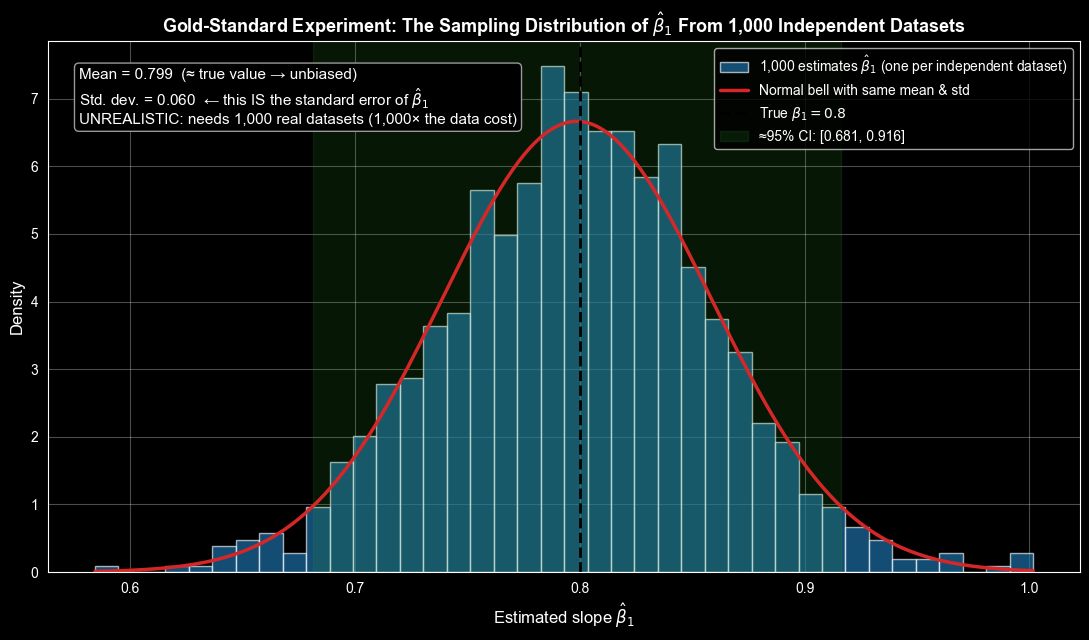

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Nature's true parameters (unknown to us in practice)
beta0, beta1, sigma = 0.0, 0.8, 0.58
N, M = 100, 1000
rng = np.random.default_rng(42)

# Draw M INDEPENDENT datasets and estimate beta1 on each one
beta1_hats = np.empty(M)
for m in range(M):
    x = rng.normal(0, 1, N)
    y = beta0 + beta1 * x + rng.normal(0, sigma, N)
    beta1_hats[m] = np.polyfit(x, y, 1)[0]            # slope estimate

mu, sd = beta1_hats.mean(), beta1_hats.std(ddof=1)
lo, hi = mu - 1.96 * sd, mu + 1.96 * sd

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.hist(beta1_hats, bins=40, density=True, color="#1f77b4", alpha=0.65, edgecolor="white",
        label=r"1,000 estimates $\hat{\beta}_1$ (one per independent dataset)")
grid = np.linspace(beta1_hats.min(), beta1_hats.max(), 300)
ax.plot(grid, stats.norm.pdf(grid, mu, sd), color="#d62728", lw=2.5, label="Normal bell with same mean & std")
ax.axvline(beta1, color="black", ls="--", lw=2, label=r"True $\beta_1 = 0.8$")
ax.axvspan(lo, hi, color="#2ca02c", alpha=0.15, label=f"≈95% CI: [{lo:.3f}, {hi:.3f}]")

ax.text(0.03, 0.95,
        f"Mean = {mu:.3f}  (≈ true value → unbiased)\nStd. dev. = {sd:.3f}  ← this IS the standard error of $\\hat{{\\beta}}_1$\n"
        "UNREALISTIC: needs 1,000 real datasets (1,000× the data cost)",
        transform=ax.transAxes, va="top", fontsize=11,
        bbox=dict(boxstyle="round", fc="black", ec="#999"))
ax.set_title(r"Gold-Standard Experiment: The Sampling Distribution of $\hat{\beta}_1$ From 1,000 Independent Datasets",
             fontsize=13, fontweight="bold")
ax.set_xlabel(r"Estimated slope $\hat{\beta}_1$", fontsize=12)
ax.set_ylabel("Density", fontsize=12)
ax.legend(fontsize=10, loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

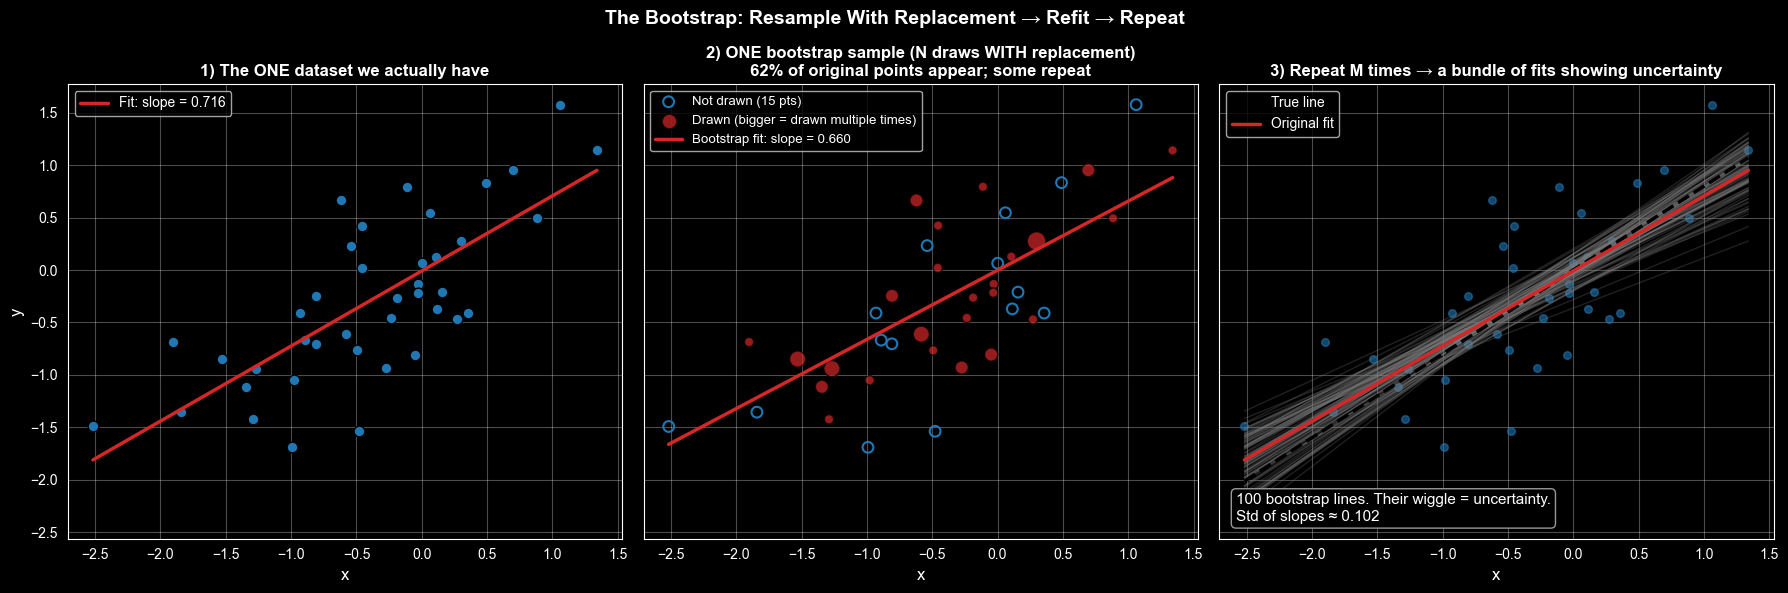

In [10]:
import numpy as np
import matplotlib.pyplot as plt

beta0, beta1, sigma, N = 0.0, 0.8, 0.58, 40   # small N so individual points are visible
rng = np.random.default_rng(7)
x = rng.normal(0, 1, N)
y = beta0 + beta1 * x + rng.normal(0, sigma, N)
xs = np.linspace(x.min(), x.max(), 100)

# ONE bootstrap sample: draw N indices uniformly WITH replacement
idx = rng.integers(0, N, N)
counts = np.bincount(idx, minlength=N)            # how many times each original point was drawn
frac_unique = (counts > 0).mean()
b_slope, b_int = np.polyfit(x[idx], y[idx], 1)
o_slope, o_int = np.polyfit(x, y, 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

# Panel 1: original dataset
axes[0].scatter(x, y, s=60, color="#1f77b4", edgecolor="black")
axes[0].plot(xs, o_int + o_slope * xs, color="#d62728", lw=2.5, label=f"Fit: slope = {o_slope:.3f}")
axes[0].set_title("1) The ONE dataset we actually have", fontsize=12, fontweight="bold")
axes[0].legend(fontsize=10, loc="upper left")

# Panel 2: one bootstrap sample (size = number of times drawn)
not_drawn = counts == 0
axes[1].scatter(x[not_drawn], y[not_drawn], s=60, facecolors="none", edgecolors="#1f77b4", lw=1.5,
                label=f"Not drawn ({not_drawn.sum()} pts)")
axes[1].scatter(x[~not_drawn], y[~not_drawn], s=45 * counts[~not_drawn], marker="o", color="#d62728", alpha=0.7,
                edgecolor="black", label="Drawn (bigger = drawn multiple times)")
axes[1].plot(xs, b_int + b_slope * xs, color="#d62728", lw=2.5, label=f"Bootstrap fit: slope = {b_slope:.3f}")
axes[1].set_title(f"2) ONE bootstrap sample (N draws WITH replacement)\n{frac_unique:.0%} of original points appear; some repeat",
                  fontsize=12, fontweight="bold")
axes[1].legend(fontsize=9.5, loc="upper left")

# Panel 3: many bootstrap fits
slopes = []
for _ in range(100):
    i = rng.integers(0, N, N)
    s, b = np.polyfit(x[i], y[i], 1)
    slopes.append(s)
    axes[2].plot(xs, b + s * xs, color="gray", alpha=0.25, lw=1)
axes[2].scatter(x, y, s=30, color="#1f77b4", alpha=0.6)
axes[2].plot(xs, beta0 + beta1 * xs, "k--", lw=2.5, label="True line")
axes[2].plot(xs, o_int + o_slope * xs, color="#d62728", lw=2.5, label="Original fit")
axes[2].text(0.03, 0.04, f"100 bootstrap lines. Their wiggle = uncertainty.\nStd of slopes ≈ {np.std(slopes, ddof=1):.3f}",
             transform=axes[2].transAxes, fontsize=11, bbox=dict(boxstyle="round", fc="black", ec="#999"))
axes[2].set_title("3) Repeat M times → a bundle of fits showing uncertainty", fontsize=12, fontweight="bold")
axes[2].legend(fontsize=10, loc="upper left")

for ax in axes:
    ax.set_xlabel("x", fontsize=12)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("y", fontsize=12)
fig.suptitle("The Bootstrap: Resample With Replacement → Refit → Repeat", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

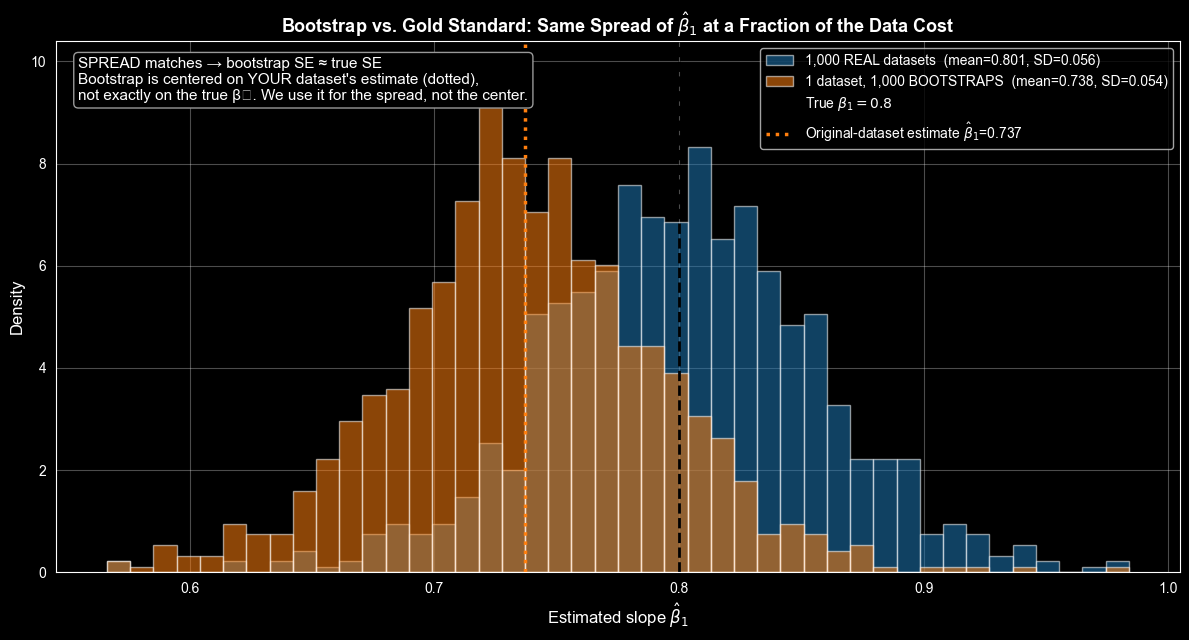

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

beta0, beta1, sigma, N, M = 0.0, 0.8, 0.58, 100, 1000
rng = np.random.default_rng(11)

def make_dataset():
    x = rng.normal(0, 1, N)
    return x, beta0 + beta1 * x + rng.normal(0, sigma, N)

# (A) Unrealistic: M independent datasets
true_est = np.array([np.polyfit(*make_dataset(), 1)[0] for _ in range(M)])

# (B) Bootstrap: ONE dataset, resampled M times with replacement
x0, y0 = make_dataset()
boot_est = np.empty(M)
for m in range(M):
    i = rng.integers(0, N, N)                         # sample N points WITH replacement
    boot_est[m] = np.polyfit(x0[i], y0[i], 1)[0]      # refit on the bootstrap sample
orig_est = np.polyfit(x0, y0, 1)[0]

m_t, s_t = true_est.mean(), true_est.std(ddof=1)
m_b, s_b = boot_est.mean(), boot_est.std(ddof=1)

fig, ax = plt.subplots(figsize=(12, 6.5))
bins = np.linspace(min(true_est.min(), boot_est.min()), max(true_est.max(), boot_est.max()), 45)
ax.hist(true_est, bins=bins, density=True, alpha=0.55, color="#1f77b4",
        label=f"1,000 REAL datasets  (mean={m_t:.3f}, SD={s_t:.3f})")
ax.hist(boot_est, bins=bins, density=True, alpha=0.55, color="#ff7f0e",
        label=f"1 dataset, 1,000 BOOTSTRAPS  (mean={m_b:.3f}, SD={s_b:.3f})")
ax.axvline(beta1, color="black", ls="--", lw=2, label=r"True $\beta_1=0.8$")
ax.axvline(orig_est, color="#ff7f0e", ls=":", lw=2.5, label=rf"Original-dataset estimate $\hat\beta_1$={orig_est:.3f}")

ax.text(0.02, 0.97,
        "SPREAD matches → bootstrap SE ≈ true SE\n"
        "Bootstrap is centered on YOUR dataset's estimate (dotted),\nnot exactly on the true β₁. We use it for the spread, not the center.",
        transform=ax.transAxes, va="top", fontsize=11, bbox=dict(boxstyle="round", fc="black", ec="#999"))
ax.set_title(r"Bootstrap vs. Gold Standard: Same Spread of $\hat{\beta}_1$ at a Fraction of the Data Cost",
             fontsize=13, fontweight="bold")
ax.set_xlabel(r"Estimated slope $\hat{\beta}_1$", fontsize=12)
ax.set_ylabel("Density", fontsize=12)
ax.legend(fontsize=10, loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()